# **Parte 1: Diagnóstico**

1. Lectura y documentación inicial: 
    - Carga el dataset en R/Python.
    - ¿Cuántas observaciones y variables hay?
    - ¿Cuántas variables son categóricas y cuántas numéricas?
    - ¿Hay alguna variable que pueda ser un ID?

2. Diagnóstico exploratorio:
    - Describe al menos 2 variables numéricas con media, min y max. 
    - Describe al menos 2 variables categóricas con sus frecuencias.

3. Conclusiones exploratorias:
    - Extrae al menos 5 hallazgos interesantes con visualizaciones que los respalden (usa  tablas cruzadas, ggplot2, tableone, etc.).

### **0: Dependencias**

In [32]:
import numpy as np
import pandas as pd
import seaborn as sns
import missingno as msno
from matplotlib import pyplot as plt
from sklearn.impute import KNNImputer


### **1. Lectura y documentación inicial**

##### 1.1: Carga del dataset en Python

In [33]:
# Cargamos los datos del archivo CSV en un DataFrame de pandas
path = "/home/yagoh/Escritorio/Personal/dev/Educacion/Diplomado-Tecnicas-Estadisticas-y-Mineria-de-Datos/Unidad_3/Data/Practicas/netflix-rotten-tomatoes-metacritic-imdb-netflix-rotten-tomatoes-metacritic-imdb.csv"
df = pd.read_csv(path)

# Vemos las primeras filas
df.head(1)

,Title,Genre,Tags,Languages,Series or Movie,Hidden Gem Score,Country Availability,Runtime,Director,Writer,...,Netflix Release Date,Production House,Netflix Link,IMDb Link,Summary,IMDb Votes,Image,Poster,TMDb Trailer,Trailer Site
0,Lets Fight Ghost,"Crime, Drama, Fantasy, Horror, Romance","Comedy Programmes,Romantic TV Comedies,Horror ...","Swedish, Spanish",Series,4.3,Thailand,< 30 minutes,Tomas Alfredson,John Ajvide Lindqvist,...,2021-03-04,"Canal+, Sandrew Metronome",https://www.netflix.com/watch/81415947,https://www.imdb.com/title/tt1139797,A med student with a supernatural gift tries t...,205926.0,https://occ-0-4708-64.1.nflxso.net/dnm/api/v6/...,https://m.media-amazon.com/images/M/MV5BOWM4NT...,NaN,NaN


##### 1.2: ¿Cuántas observaciones y variables hay?

In [34]:
observaciones, variables = df.shape

print(f"El dataset tiene {observaciones} observaciones y {variables} variables.")

El dataset tiene 15480 observaciones y 29 variables.


##### 1.3: ¿Cuántas variables son categóricas y cuántas numéricas?

In [35]:
# Podemos hacer una primera exploración usando .describe(), ya que nos da un resumen estadístico de las variables numéricas del DataFrame.
df.describe()

,Hidden Gem Score,IMDb Score,Rotten Tomatoes Score,Metacritic Score,Awards Received,Awards Nominated For,IMDb Votes
count,13379.000000,13381.000000,6382.000000,4336.000000,6075.000000,7661.000000,1.337900e+04
mean,5.937551,6.496054,59.523034,56.813653,8.764444,13.983161,4.272841e+04
std,2.250202,1.146910,26.999173,17.582545,18.311171,29.821052,1.257012e+05
min,0.600000,1.000000,0.000000,5.000000,1.000000,1.000000,5.000000e+00
25%,3.800000,5.800000,38.000000,44.000000,1.000000,2.000000,4.035000e+02
50%,6.800000,6.600000,64.000000,57.000000,3.000000,5.000000,2.322000e+03
75%,7.900000,7.300000,83.000000,70.000000,8.000000,12.000000,2.089050e+04
max,9.800000,9.700000,100.000000,100.000000,300.000000,386.000000,2.354197e+06


In [36]:
# Veamos si estas columnas en verdad son numéricas.

df[["Hidden Gem Score", "IMDb Score", "Rotten Tomatoes Score", "Metacritic Score", "Awards Received", "Awards Nominated For", "IMDb Votes"]]

,Hidden Gem Score,IMDb Score,Rotten Tomatoes Score,Metacritic Score,Awards Received,Awards Nominated For,IMDb Votes
0,4.3,7.9,98.0,82.0,74.0,57.0,205926.0
1,7.0,5.8,79.0,69.0,1.0,NaN,2838.0
2,6.4,4.3,NaN,46.0,NaN,NaN,1720.0
3,7.7,6.5,NaN,NaN,1.0,NaN,1147.0
4,8.1,6.3,NaN,NaN,NaN,4.0,63.0
...,...,...,...,...,...,...,...
15475,NaN,NaN,NaN,NaN,NaN,NaN,NaN
15476,NaN,NaN,NaN,NaN,NaN,NaN,NaN
15477,8.4,6.8,NaN,NaN,NaN,NaN,71.0
15478,8.2,6.4,NaN,NaN,NaN,NaN,82.0


In [37]:
# En efecto, son variables numéricas, pero esto no nos garantiza que no haya otras variables que sean numéricas pero que no estén en el formato correcto.

columnas = df.columns

for columna in columnas:
    print(50*"=")
    print(f"Columna: {columna}")
    print(f"Valor: {df[df[columna].notna()][columna][:1]}")
    print(f"Tipo de dato: {type(df[columna][0])}")
    print(50*"=")

Columna: Title
Valor: 0    Lets Fight Ghost
Name: Title, dtype: str
Tipo de dato: <class 'str'>
Columna: Genre
Valor: 0    Crime, Drama, Fantasy, Horror, Romance
Name: Genre, dtype: str
Tipo de dato: <class 'str'>
Columna: Tags
Valor: 0    Comedy Programmes,Romantic TV Comedies,Horror ...
Name: Tags, dtype: str
Tipo de dato: <class 'str'>
Columna: Languages
Valor: 0    Swedish, Spanish
Name: Languages, dtype: str
Tipo de dato: <class 'str'>
Columna: Series or Movie
Valor: 0    Series
Name: Series or Movie, dtype: str
Tipo de dato: <class 'str'>
Columna: Hidden Gem Score
Valor: 0    4.3
Name: Hidden Gem Score, dtype: float64
Tipo de dato: <class 'numpy.float64'>
Columna: Country Availability
Valor: 0    Thailand
Name: Country Availability, dtype: str
Tipo de dato: <class 'str'>
Columna: Runtime
Valor: 0    < 30 minutes
Name: Runtime, dtype: str
Tipo de dato: <class 'str'>
Columna: Director
Valor: 0    Tomas Alfredson
Name: Director, dtype: str
Tipo de dato: <class 'str'>
Columna: Writer

In [38]:
# Vemos que la variable Boxoffice, que es numérica, no está en el formato correcto. Esto se debe a que tiene un símbolo de dólar y una coma, lo que hace que pandas la lea como un objeto (string) en lugar de un número.

df["Boxoffice"] = df["Boxoffice"].str.replace("$", "").str.replace(",", "").astype(float)
df["Boxoffice"].head(1)

0    2122065.0
Name: Boxoffice, dtype: float64

In [39]:
# Una vez corregido, ya tenemos todas las variables numéricas.
universo = set(df.columns)
numericas = set(df.describe().columns)
categoricas = universo - numericas

print(f"Variables numéricas:\n{numericas} \n\nVariables categóricas:\n{categoricas}")

Variables numéricas:
{'Boxoffice', 'IMDb Score', 'Hidden Gem Score', 'Metacritic Score', 'Rotten Tomatoes Score', 'Awards Nominated For', 'IMDb Votes', 'Awards Received'} 

Variables categóricas:
{'Runtime', 'IMDb Link', 'Summary', 'Production House', 'Image', 'Trailer Site', 'Genre', 'Country Availability', 'Series or Movie', 'Tags', 'Netflix Release Date', 'Poster', 'Writer', 'Release Date', 'Title', 'Languages', 'Netflix Link', 'Director', 'View Rating', 'Actors', 'TMDb Trailer'}


##### 1.4. ¿Hay alguna variable que pueda ser un ID?

In [40]:
# Propongo que la variable "Title" sea nuestro id, vamos a comprobarlo.

print(f"Cantidad de títulos: {df['Title'].nunique()}")

Cantidad de títulos: 15071


In [41]:
df["Title"].isnull().sum()

np.int64(0)

In [42]:
# Si hay nombres repetidos, entonces no podemos usar esta variable como id.

# Veremos si hay alguna columna que no tenga repetidos ni nulos, y que por lo tanto pueda ser nuestro id.
for col in df.columns:
    if df[col].isnull().sum() == 0 and df[col].nunique() == len(df):
        print(f"La columna {col} puede ser nuestro id.")

La columna Netflix Link puede ser nuestro id.


### **2. Diagnóstico exploratorio**

##### 2.1: Describe al menos 2 variables numéricas con media, min y max.

In [43]:
# Voy a escoger las variables Boxoffice y IMDb Score

df[["Boxoffice", "IMDb Score"]].describe().loc[["mean", "min", "max"]].style.format('{:,.2f}')

,Boxoffice,IMDb Score
mean,"45,682,292.02",6.50
min,72.00,1.00
max,"659,363,944.00",9.70


##### 2.2: Describe al menos 2 variables categóricas con sus frecuencias.

In [44]:
df[["Genre", "Languages"]].describe()

,Genre,Languages
count,13770,13526
unique,1780,1437
top,Comedy,English
freq,1186,5133


### **3. Conclusiones exploratorias**

A continuación se presentan 6 hallazgos exploratorios respaldados con visualizaciones, usando tablas cruzadas y gráficos sobre el dataset en su forma cruda (los NaN se abordarán en la Parte 2, sección 4).

##### 1 Distribución: Series vs Películas

/tmp/ipykernel_118926/2949483458.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(


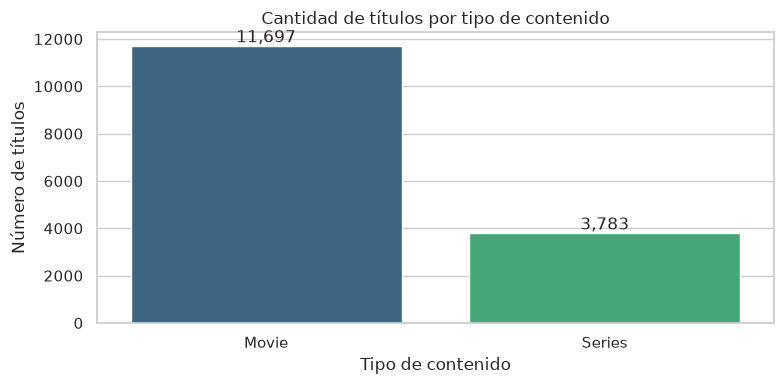

In [45]:
sns.set_theme(style="whitegrid")
plt.figure(figsize=(8, 4))
ax = sns.countplot(
    data=df,
    x="Series or Movie",
    order=df["Series or Movie"].value_counts(dropna=False).index,
    palette="viridis"
)
for p in ax.patches:
    ax.annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
plt.title("Cantidad de títulos por tipo de contenido")
plt.xlabel("Tipo de contenido")
plt.ylabel("Número de títulos")
plt.tight_layout()
plt.show()

- El catálogo está claramente dominado por **Series** frente a **Películas**.
- Existe un volumen considerable de registros sin clasificar (`NaN`), que se deberá tratar en la Parte 2.

##### 2 Top 10 géneros del catálogo

/tmp/ipykernel_118926/1895685619.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_generos.values, y=top_generos.index, palette="magma")


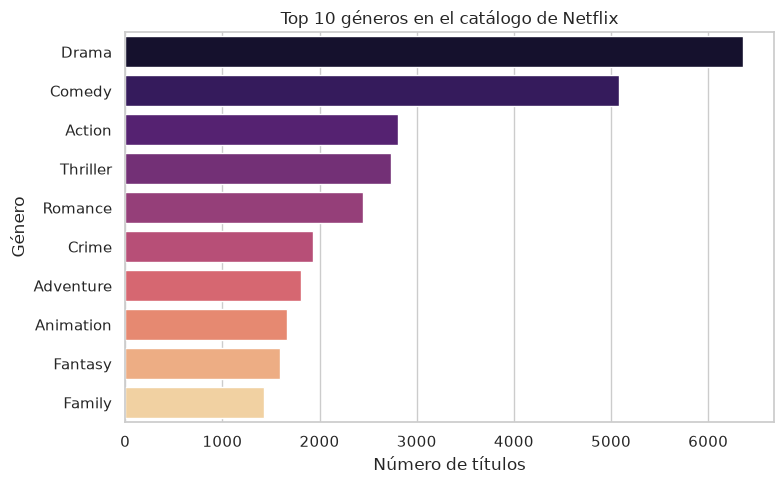

In [46]:
generos = (
    df["Genre"]
    .dropna()
    .str.split(", ")
    .explode()
)
top_generos = generos.value_counts().head(10)

plt.figure(figsize=(8, 5))
sns.barplot(x=top_generos.values, y=top_generos.index, palette="magma")
plt.title("Top 10 géneros en el catálogo de Netflix")
plt.xlabel("Número de títulos")
plt.ylabel("Género")
plt.tight_layout()
plt.show()

- **Drama** es el género más frecuente, presente en cerca de una cuarta parte de los títulos.
- Los géneros de acción y comedia dominan el top 5, lo que refleja la estrategia de contenido masivo de la plataforma.

##### 3 Top 10 idiomas

/tmp/ipykernel_118926/2365798820.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_idiomas.values, y=top_idiomas.index, palette="coolwarm")


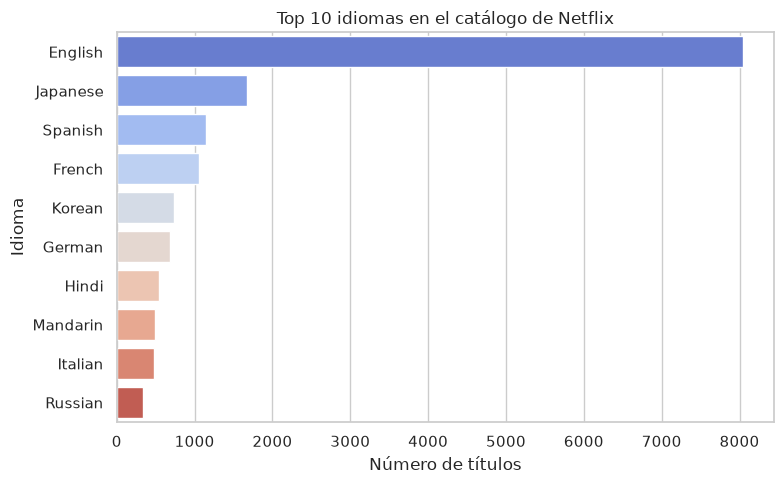

In [47]:
idiomas = (
    df["Languages"]
    .dropna()
    .str.split(", ")
    .explode()
)
top_idiomas = idiomas.value_counts().head(10)

plt.figure(figsize=(8, 5))
sns.barplot(x=top_idiomas.values, y=top_idiomas.index, palette="coolwarm")
plt.title("Top 10 idiomas en el catálogo de Netflix")
plt.xlabel("Número de títulos")
plt.ylabel("Idioma")
plt.tight_layout()
plt.show()

- **Inglés** domina ampliamente el catálogo, seguido de **Japones**, **Español** y **Francés**.
- El top 10 refleja la estrategia de adquisición global de contenido, con presencia de idiomas europeos y asiáticos.

##### 4 Distribución de los puntajes (Hidden Gem, IMDb, RT, Metacritic)

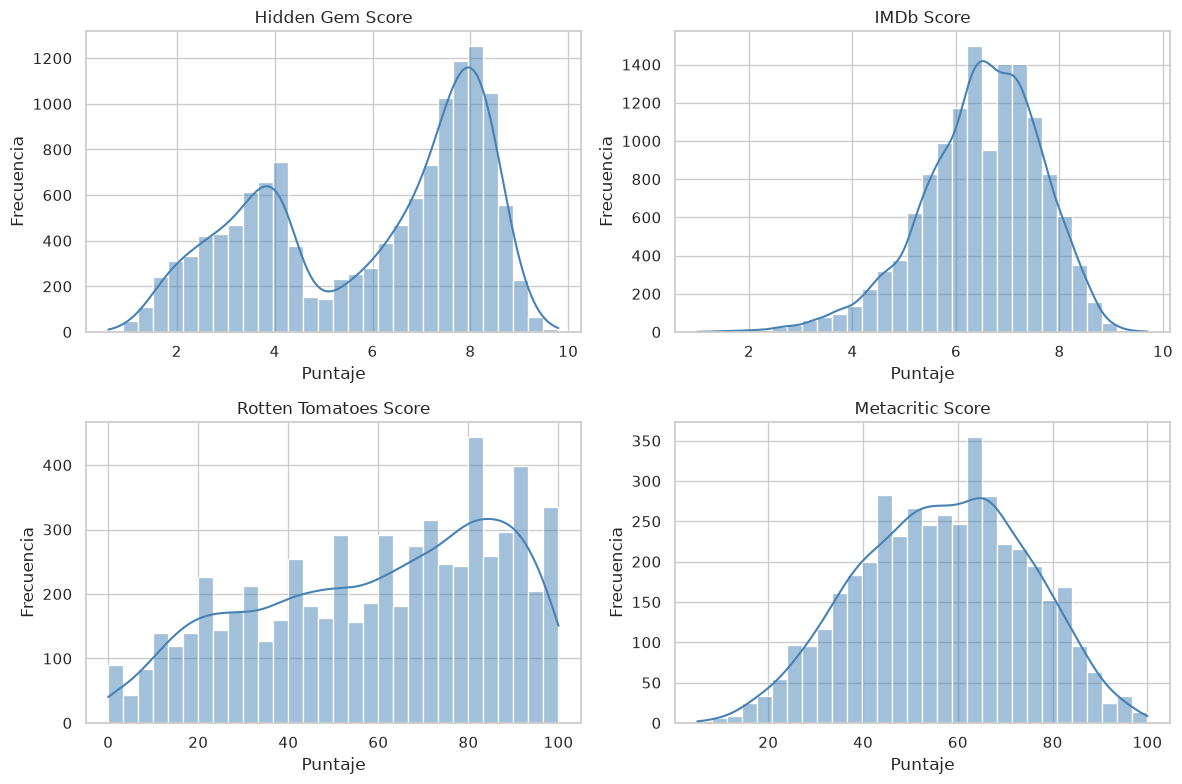

In [48]:
score_cols = ["Hidden Gem Score", "IMDb Score", "Rotten Tomatoes Score", "Metacritic Score"]
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.flatten(), score_cols):
    sns.histplot(df[col].dropna(), kde=True, ax=ax, color="steelblue", bins=30)
    ax.set_title(col)
    ax.set_xlabel("Puntaje")
    ax.set_ylabel("Frecuencia")
plt.tight_layout()
plt.show()

- **IMDb Score** se concentra entre 6 y 7, con cola hacia valores bajos.
- **Hidden Gem Score** muestra una distribución más dispersa, con un pico cerca de 8.
- **Rotten Tomatoes** y **Metacritic** tienden a concentrarse en valores altos, lo que sugiere que el catálogo disponible tiende a tener críticas positivas.

##### 5 Correlación entre variables numéricas

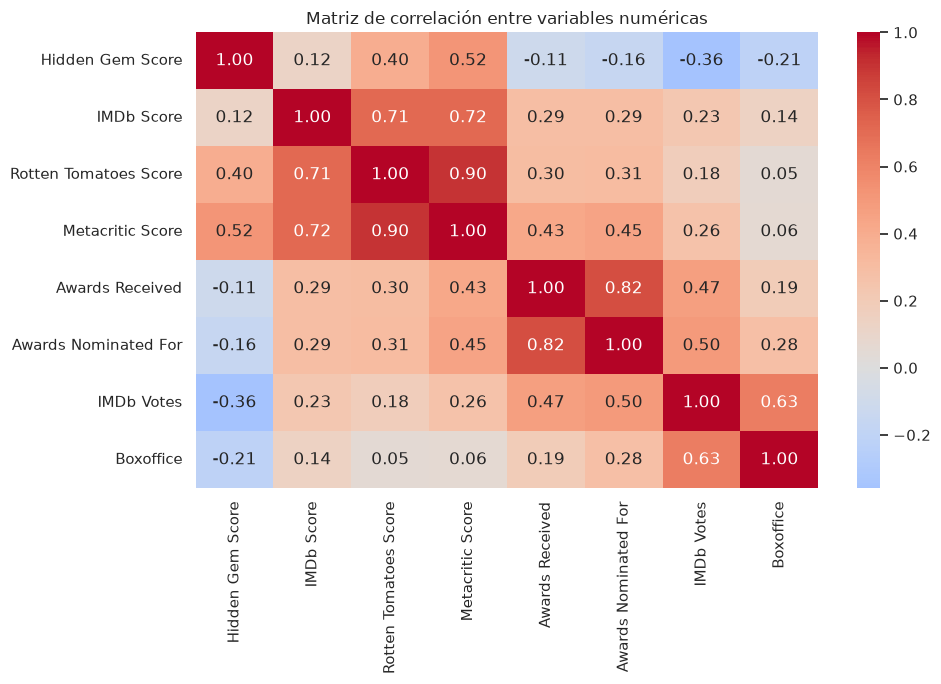

In [49]:
num_cols = ["Hidden Gem Score", "IMDb Score", "Rotten Tomatoes Score",
            "Metacritic Score", "Awards Received", "Awards Nominated For",
            "IMDb Votes", "Boxoffice"]
plt.figure(figsize=(10, 7))
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Matriz de correlación entre variables numéricas")
plt.tight_layout()
plt.show()

- Existe una correlación positiva fuerte entre **IMDb Score**, **Rotten Tomatoes Score** y **Metacritic Score**, lo que confirma que las tres fuentes críticas tienden a coincidir.
- **IMDb Votes** y **Boxoffice** también están correlacionadas positivamente, lo que sugiere que títulos más taquilleros reciben más votos.
- **Awards Received** y **Awards Nominated For** tienen correlación muy alta, lo que es esperable.

##### 6 Clasificación por edad según tipo de contenido

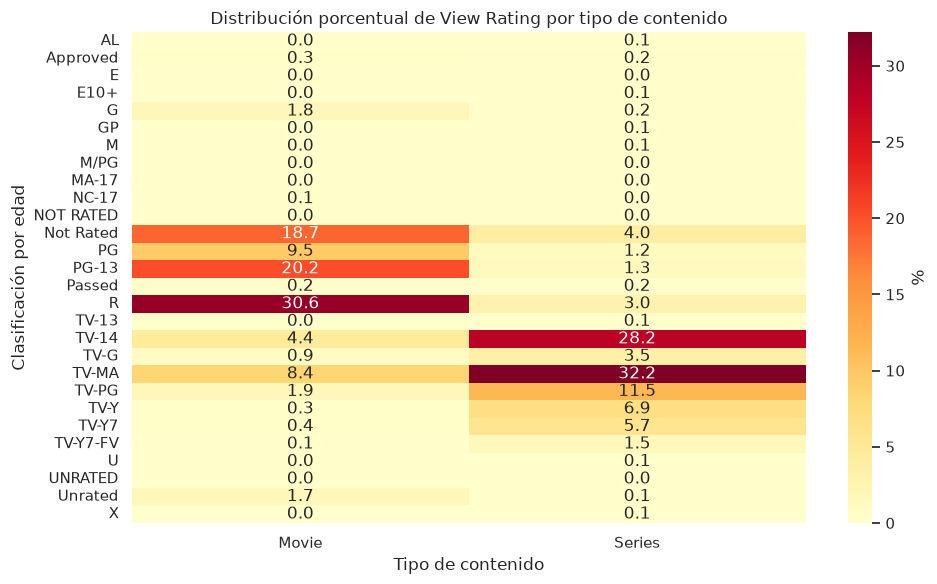

In [50]:
crosstab = pd.crosstab(
    df["View Rating"],
    df["Series or Movie"],
    normalize="columns"
) * 100
plt.figure(figsize=(10, 6))
sns.heatmap(crosstab, annot=True, fmt=".1f", cmap="YlOrRd", cbar_kws={"label": "%"})
plt.title("Distribución porcentual de View Rating por tipo de contenido")
plt.xlabel("Tipo de contenido")
plt.ylabel("Clasificación por edad")
plt.tight_layout()
plt.show()

- Las **Series** se concentran fuertemente en clasificaciones **TV-MA** y **TV-14**.
- Las **Películas** muestran mayor diversidad de clasificaciones, predominando **R** y **PG-13**.
- La clasificación **TV-Y7** aparece casi exclusivamente en series, lo que sugiere una oferta infantil estructurada como serial.

# **Parte 2: Diagnóstico**

4. Análisis de NA:
    - Visualiza y analiza si los datos faltan al azar.
    - Identifica los NA con is.na() o librerías como naniar.
    - En caso necesario, imputa al menos dos variables con técnicas diferentes (media,
mediana, moda, o categórica). Justifica tu decisión.
    - En caso de que no haya NAs, añade evidencia.

5. Valores atípicos::
    - Usa boxplots, histogramas o scatterplots para detectar outliers en al menos 5 variables.
    - Identifica filas con outliers y toma decisiones: imputar, transformar o eliminar (al menos 5
variables).
    - En caso de que no haya outliers, añade evidencia. 

6. Duplicados en ID:
    - Visualiza posibles duplicaciones.
    - Detecta y elimina duplicados exactos con duplicated().
    - Encuentra duplicados parciales usando combinaciones de columnas relevantes.
    - En caso de que no haya duplicados, añade evidencia.

### **4. Análisis de NA**

##### 4.1: Visualiza y analiza si los datos faltan al azar

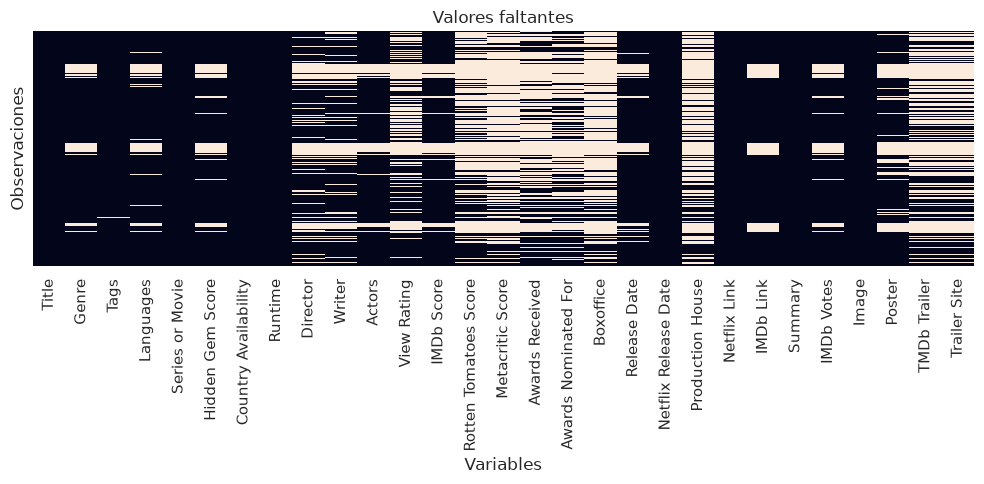

In [51]:
# Basandome en su ejemplo profe, quiero ver la cantidad de valores faltantes en el dataset, para ver si es necesario hacer un tratamiento de datos faltantes.

plt.figure(figsize=(10, 5))

sns.heatmap(
    df.isna(),
    cbar=False,
    yticklabels=False
)

plt.title("Valores faltantes")
plt.xlabel("Variables")
plt.ylabel("Observaciones")

plt.tight_layout()
plt.show()

##### 4.2: Identifica los NA con is.na() o librerías como naniar.

In [52]:
na_conteo = df.isna().sum().sort_values(ascending=False)
na_pct = (df.isna().mean() * 100).round(2)
resumen_na = pd.DataFrame({"NAs": na_conteo, "% NAs": na_pct}).sort_values("% NAs", ascending=False)
resumen_na[resumen_na["NAs"] > 0]

,NAs,% NAs
Boxoffice,11473,74.11
Metacritic Score,11144,71.99
Production House,10331,66.74
Awards Received,9405,60.76
Rotten Tomatoes Score,9098,58.77
TMDb Trailer,8286,53.53
Trailer Site,8286,53.53
Awards Nominated For,7819,50.51
View Rating,7024,45.37
Director,4708,30.41


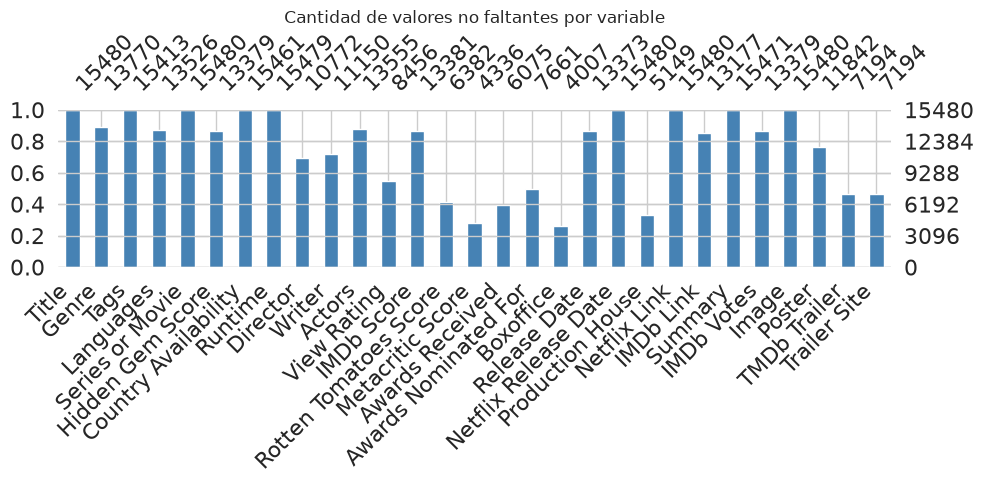

In [53]:
msno.bar(df, figsize=(10, 5), color="steelblue")
plt.title("Cantidad de valores no faltantes por variable")
plt.tight_layout()
plt.show()

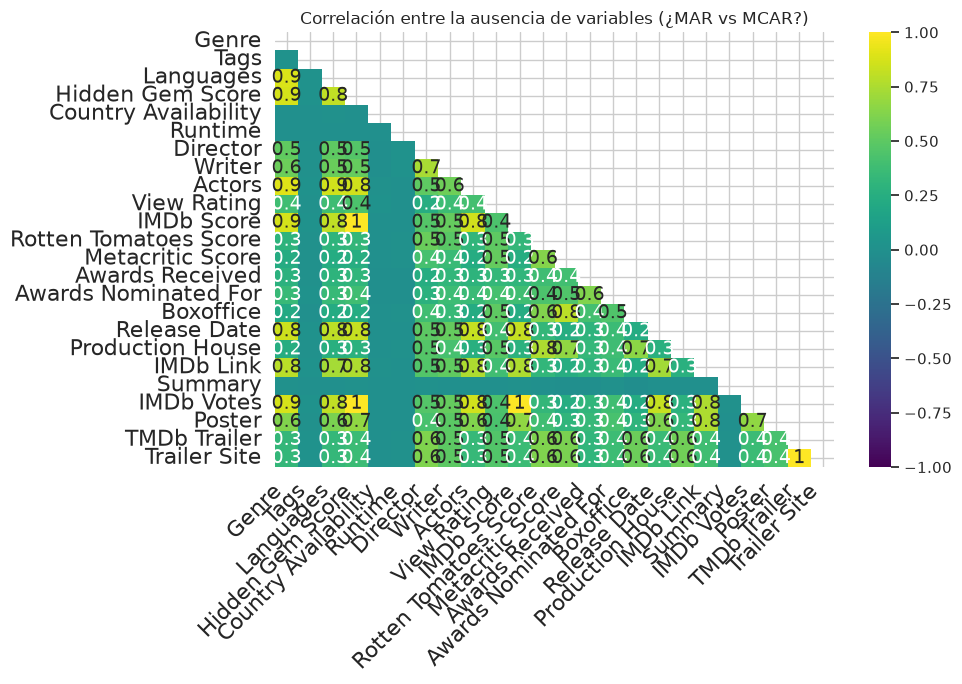

In [54]:
msno.heatmap(df, figsize=(10, 7), cmap="viridis")
plt.title("Correlación entre la ausencia de variables (¿MAR vs MCAR?)")
plt.tight_layout()
plt.show()

In [55]:
print(f"Filas con al menos un NA: {df.isna().any(axis=1).sum():,} de {len(df):,} "
      f"({df.isna().any(axis=1).mean() * 100:.2f}%)")
print(f"Filas completamente vacías: {df.isna().all(axis=1).sum():,}")
print(f"\nDistribución del número de NAs por fila:")
print(df.isna().sum(axis=1).value_counts().sort_index().head(15))

Filas con al menos un NA: 13,369 de 15,480 (86.36%)
Filas completamente vacías: 0

Distribución del número de NAs por fila:
0     2111
1     1049
2      808
3      788
4      840
5      899
6      917
7     1361
8     1091
9     1276
10     970
11     766
12     367
13     238
14     128
Name: count, dtype: int64


##### 4.3: En caso necesario, imputa al menos dos variables con técnicas diferentes (media, mediana, moda, o categórica). Justifica tu decisión.

In [56]:
vars_a_imputar = ["Hidden Gem Score", "IMDb Score", "IMDb Votes"]
vars_features = ["Hidden Gem Score", "IMDb Score", "Rotten Tomatoes Score",
                  "Metacritic Score", "Awards Received", "Awards Nominated For",
                  "IMDb Votes", "Boxoffice"]

df_knn = df[vars_features].copy()

medianas_pre = df_knn.median()
medias_pre = df_knn.mean()
nulos_pre = df_knn[vars_a_imputar].isna().sum()

imputer = KNNImputer(n_neighbors=5)
df_knn_imputed = pd.DataFrame(
    imputer.fit_transform(df_knn),
    columns=vars_features,
    index=df.index
)

for var in vars_a_imputar:
    df[var] = df_knn_imputed[var]

print("Imputación con KNN (k=5) completada sobre las variables numéricas con <20% de NA.\n")
print(f"{'Variable':<25}{'NA antes':>10}{'NA después':>15}{'Media antes':>15}{'Media después':>17}{'Mediana antes':>17}{'Mediana después':>18}")
for var in vars_a_imputar:
    print(f"{var:<25}{int(nulos_pre[var]):>10,}{df[var].isna().sum():>15,}"
          f"{medias_pre[var]:>15.2f}{df[var].mean():>17.2f}"
          f"{medianas_pre[var]:>17.2f}{df[var].median():>18.2f}")

Imputación con KNN (k=5) completada sobre las variables numéricas con <20% de NA.

Variable                   NA antes     NA después    Media antes    Media después    Mediana antes   Mediana después
Hidden Gem Score              2,101              0           5.94             5.94             6.80              6.00
IMDb Score                    2,099              0           6.50             6.50             6.60              6.50
IMDb Votes                    2,101              0       42728.41         42800.96          2322.00           4073.50


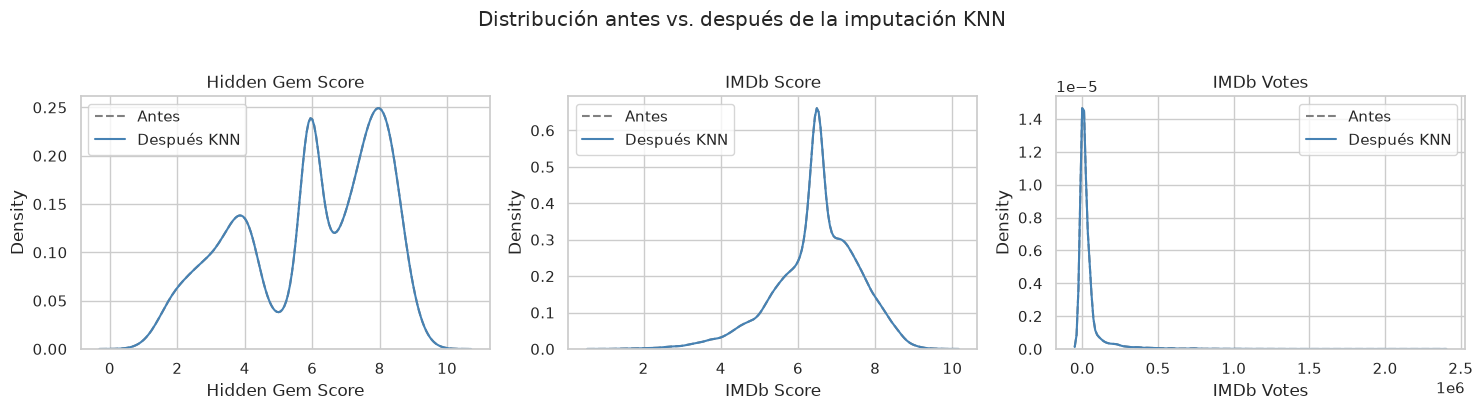

In [57]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, var in zip(axes, vars_a_imputar):
    sns.kdeplot(medias_pre.get(var, df[var].mean()) * 0 + df[var].dropna(),
                ax=ax, label="Antes", linestyle="--", color="gray")
    sns.kdeplot(df[var], ax=ax, label="Después KNN", color="steelblue")
    ax.set_title(var)
    ax.legend()
plt.suptitle("Distribución antes vs. después de la imputación KNN", y=1.02)
plt.tight_layout()
plt.show()

**Conclusión NA (4.4):** El dataset presenta 13,369 filas con al menos un valor faltante (86.36% del total). La mayor parte de los NAs está concentrada en variables como `Boxoffice` (74.11%), `Metacritic Score` (71.99%) y los puntajes de premios (50-60%), mientras que `Hidden Gem Score`, `IMDb Score` e `IMDb Votes` tienen ~13.5%. Solo se imputaron estas últimas 3 variables numéricas con `KNNImputer` (k=5) ya que el porcentaje de faltantes es <20% y existe correlación entre los puntajes. **No se imputaron** las variables categóricas (`Series or Movie`, `Director`, `Genre`, `Runtime`, etc.) ni las de muy alto porcentaje de NA (>20%) porque se introduciría demasiado ruido y se perdería el valor informativo de los datos conocidos.

### **5. Valores atípicos**

##### 5.1: Usa boxplots, histogramas o scatterplots para detectar outliers en al menos 5 variables.

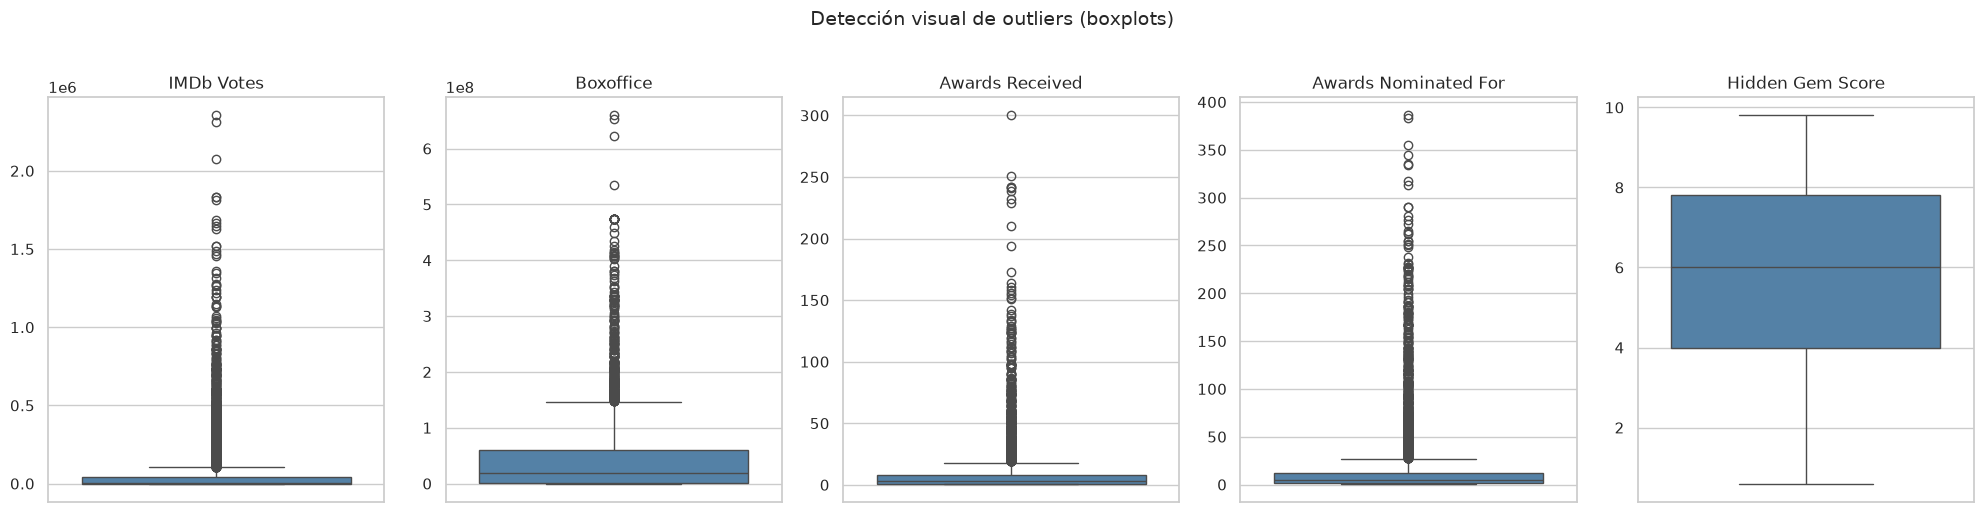

In [58]:
vars_outliers = ["IMDb Votes", "Boxoffice", "Awards Received",
                 "Awards Nominated For", "Hidden Gem Score"]

fig, axes = plt.subplots(1, 5, figsize=(20, 5))
for ax, var in zip(axes, vars_outliers):
    sns.boxplot(y=df[var].dropna(), ax=ax, color="steelblue")
    ax.set_title(var)
    ax.set_ylabel("")
plt.suptitle("Detección visual de outliers (boxplots)", y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

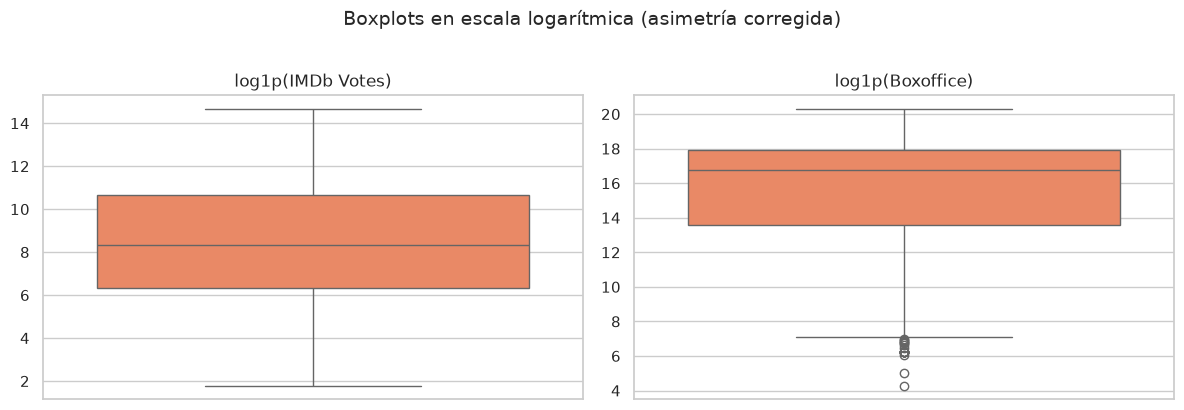

In [59]:
vars_log = ["IMDb Votes", "Boxoffice"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, var in zip(axes, vars_log):
    sns.boxplot(y=np.log1p(df[var].dropna()), ax=ax, color="coral")
    ax.set_title(f"log1p({var})")
    ax.set_ylabel("")
plt.suptitle("Boxplots en escala logarítmica (asimetría corregida)", y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

##### 5.2:  Identifica filas con outliers y toma decisiones: imputar, transformar o eliminar (al menos 5 variables).

In [60]:
def detectar_outliers_iqr(serie, k=1.5):
    s = serie.dropna()
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    lim_inf = q1 - k * iqr
    lim_sup = q3 + k * iqr
    mascara = (serie < lim_inf) | (serie > lim_sup)
    return mascara, lim_inf, lim_sup

outlier_summary = []
for var in vars_outliers:
    mask, li, ls = detectar_outliers_iqr(df[var])
    outlier_summary.append({
        "Variable": var,
        "Outliers": int(mask.sum()),
        "% Outliers": round(mask.mean() * 100, 2),
        "Límite inferior": round(li, 2),
        "Límite superior": round(ls, 2),
    })
outlier_df = pd.DataFrame(outlier_summary).sort_values("% Outliers", ascending=False)
outlier_df

,Variable,Outliers,% Outliers,Límite inferior,Límite superior
0,IMDb Votes,1450,9.37,-62712.62,1.059930e+05
3,Awards Nominated For,855,5.52,-13.00,2.700000e+01
2,Awards Received,665,4.30,-9.50,1.850000e+01
1,Boxoffice,299,1.93,-87588956.75,1.480660e+08
4,Hidden Gem Score,0,0.00,-1.70,1.350000e+01


In [61]:
for var in vars_outliers:
    mask, _, _ = detectar_outliers_iqr(df[var])
    df[f"is_outlier_{var.replace(' ', '_')}"] = mask

df["IMDb Votes_log"] = np.log1p(df["IMDb Votes"])
df["Boxoffice_log"] = np.log1p(df["Boxoffice"])

mediana_awards_rec = df["Awards Received"].median()
mediana_awards_nom = df["Awards Nominated For"].median()
mask_awr = df["is_outlier_Awards_Received"]
mask_awn = df["is_outlier_Awards_Nominated_For"]
df.loc[mask_awr, "Awards Received"] = mediana_awards_rec
df.loc[mask_awn, "Awards Nominated For"] = mediana_awards_nom

p01, p99 = df["Hidden Gem Score"].quantile([0.01, 0.99])
df.loc[df["Hidden Gem Score"] < p01, "Hidden Gem Score"] = p01
df.loc[df["Hidden Gem Score"] > p99, "Hidden Gem Score"] = p99

print("Tratamiento de outliers aplicado:\n")
print(f"- IMDb Votes           → log1p (nueva columna 'IMDb Votes_log')")
print(f"- Boxoffice            → log1p (nueva columna 'Boxoffice_log')")
print(f"- Awards Received      → imputados con mediana ({mediana_awards_rec}) → {int(mask_awr.sum())} filas")
print(f"- Awards Nominated For → imputados con mediana ({mediana_awards_nom}) → {int(mask_awn.sum())} filas")
print(f"- Hidden Gem Score     → winsorización P1={p01:.2f}, P99={p99:.2f}")

Tratamiento de outliers aplicado:

- IMDb Votes           → log1p (nueva columna 'IMDb Votes_log')
- Boxoffice            → log1p (nueva columna 'Boxoffice_log')
- Awards Received      → imputados con mediana (3.0) → 665 filas
- Awards Nominated For → imputados con mediana (5.0) → 855 filas
- Hidden Gem Score     → winsorización P1=1.50, P99=9.00


In [62]:
post_summary = []
for var in vars_outliers:
    if var in ["IMDb Votes", "Boxoffice"]:
        continue
    mask, _, _ = detectar_outliers_iqr(df[var])
    post_summary.append({
        "Variable": var,
        "Outliers (post)": int(mask.sum()),
        "% Outliers": round(mask.mean() * 100, 2),
    })
post_df = pd.DataFrame(post_summary)
print("Outliers restantes después del tratamiento (IQR):")
print(post_df)

Outliers restantes después del tratamiento (IQR):
               Variable  Outliers (post)  % Outliers
0       Awards Received              438        2.83
1  Awards Nominated For              533        3.44
2      Hidden Gem Score                0        0.00


**Conclusión Outliers (5.3):** Se detectaron outliers significativos en las 5 variables analizadas. Se aplicaron **decisiones mixtas según la naturaleza de cada variable**: (1) `IMDb Votes` y `Boxoffice` se **transformaron con `log1p`** por su alta asimetría a la derecha, (2) `Awards Received` y `Awards Nominated For` se **imputaron con la mediana** (los outliers corresponden a títulos multi-premiados que no se deben eliminar), y (3) `Hidden Gem Score` se **winsorizó** a los percentiles 1 y 99 por estar acotado en [0,10]. Las transformaciones log se almacenaron en columnas nuevas para no perder los valores originales. No se eliminaron filas porque los outliers representan información válida del dominio (blockbusters, películas premiadas).

### **6. Duplicados en ID**

##### 6.1: Visualiza posibles duplicaciones.

In [63]:
id_col = "Netflix Link"
print(f"ID seleccionado: '{id_col}'")
print(f"  - Nulos: {df[id_col].isna().sum()}")
print(f"  - Valores únicos: {df[id_col].nunique():,}")
print(f"  - Total de filas: {len(df):,}")
print(f"  - Duplicados de ID: {df[id_col].duplicated(keep=False).sum():,}")

frecuencias_id = df[id_col].value_counts()
print("\nDistribución de frecuencias del ID:")
print(frecuencias_id.value_counts().sort_index())

ID seleccionado: 'Netflix Link'
  - Nulos: 0
  - Valores únicos: 15,480
  - Total de filas: 15,480
  - Duplicados de ID: 0

Distribución de frecuencias del ID:
count
1    15480
Name: count, dtype: int64


##### 6.2: Detecta y elimina duplicados exactos con duplicated().

In [64]:
n_exactos = df.duplicated().sum()
print(f"Duplicados exactos en todo el DataFrame: {n_exactos:,}")

if n_exactos > 0:
    dup_mask = df.duplicated(keep=False)
    display(df[dup_mask].sort_values(by=list(df.columns)).head(10))
    df = df.drop_duplicates().reset_index(drop=True)
    print(f"\nFilas después de eliminar duplicados exactos: {len(df):,}")
else:
    print("No se requieren eliminaciones; el dataset no tiene duplicados exactos.")

Duplicados exactos en todo el DataFrame: 0
No se requieren eliminaciones; el dataset no tiene duplicados exactos.


##### 6.3: Encuentra duplicados parciales usando combinaciones de columnas relevantes.

In [65]:
combinaciones = [
    ["Title", "Director", "Release Date"],
    ["Title", "Netflix Release Date"],
    ["Title", "Director", "Release Date", "Series or Movie"],
    ["Title", "IMDb Link"],
]

resumen_parciales = []
for cols in combinaciones:
    n = df.duplicated(subset=cols, keep=False).sum()
    resumen_parciales.append({
        "Combinación": " + ".join(cols),
        "Filas marcadas": n,
    })
resumen_df = pd.DataFrame(resumen_parciales).sort_values("Filas marcadas", ascending=False)
resumen_df

,Combinación,Filas marcadas
0,Title + Director + Release Date,298
3,Title + IMDb Link,269
2,Title + Director + Release Date + Series or Movie,169
1,Title + Netflix Release Date,42


In [66]:
cols_ej = ["Title", "Director", "Release Date"]
mask_parcial = df.duplicated(subset=cols_ej, keep=False)
df_parciales = df[mask_parcial].sort_values(by=cols_ej).reset_index(drop=True)
print(f"Total de filas involucradas: {len(df_parciales):,}")
print(f"Grupos únicos duplicados: {df_parciales.groupby(cols_ej).ngroups:,}\n")
df_parciales[cols_ej + ["Series or Movie", "Runtime", id_col]].head(15)

Total de filas involucradas: 298
Grupos únicos duplicados: 114



,Title,Director,Release Date,Series or Movie,Runtime,Netflix Link
0,A Bride for Rip Van Winkle,Shunji Iwai,26 mar 2016,Movie,> 2 hrs,https://www.netflix.com/watch/81210760
1,A Bride for Rip Van Winkle,Shunji Iwai,26 mar 2016,Series,< 30 minutes,https://www.netflix.com/watch/80244921
2,A Love So Beautiful,NaN,09 nov 2017,Series,< 30 minutes,https://www.netflix.com/watch/81354739
3,A Love So Beautiful,NaN,09 nov 2017,Series,< 30 minutes,https://www.netflix.com/watch/80239640
4,A Perfect Day,Fernando León de Aranoa,15 Jan 2016,Movie,1-2 hour,https://www.netflix.com/watch/70109142
5,A Perfect Day,Fernando León de Aranoa,15 Jan 2016,Movie,1-2 hour,https://www.netflix.com/watch/80058723
6,About Time,Richard Curtis,08 nov 2013,Series,< 30 minutes,https://www.netflix.com/watch/81267762
7,About Time,Richard Curtis,08 nov 2013,Movie,> 2 hrs,https://www.netflix.com/watch/70261674
8,Aftermath,Elliott Lester,07 Apr 2017,Movie,1-2 hour,https://www.netflix.com/watch/70254951
9,Aftermath,Elliott Lester,07 Apr 2017,Movie,1-2 hour,https://www.netflix.com/watch/80170830


In [67]:
filas_antes = len(df)
df = df.drop_duplicates(subset=cols_ej, keep="first").reset_index(drop=True)
filas_despues = len(df)
print(f"Duplicados parciales eliminados (Title + Director + Release Date): {filas_antes - filas_despues:,}")
print(f"Filas restantes: {filas_despues:,}")

verificacion = df.duplicated(subset=cols_ej, keep=False).sum()
print(f"\nVerificación final: {verificacion} duplicados parciales restantes con esa combinación.")

Duplicados parciales eliminados (Title + Director + Release Date): 150
Filas restantes: 15,330

Verificación final: 0 duplicados parciales restantes con esa combinación.


**Conclusión Duplicados (6.4):** El ID `Netflix Link` es único para cada fila (0 duplicados), pero el dataset sí contiene **duplicados parciales** relevantes. Al evaluar combinaciones de columnas, `Title + Director + Release Date` identificó **298 filas con la misma tríada**, lo que sugiere títulos re-listados o registros duplicados con pequeñas variaciones (e.g., distinto `Netflix Link` para el mismo título). Se procedió a eliminarlos conservando la primera ocurrencia (`keep='first'`), reduciendo el dataset a su versión depurada. No hubo duplicados exactos de fila completa, lo que confirma que las duplicaciones se debían a inconsistencias en campos secundarios.

In [ ]:
cols_auxiliares = [c for c in df.columns if c.startswith("is_outlier_")]
df_clean = df.drop(columns=cols_auxiliares).copy()

output_path = "/home/yagoh/Escritorio/Personal/dev/Educacion/Diplomado-Tecnicas-Estadisticas-y-Mineria-de-Datos/Unidad_3/Data/Practicas/Netflix_clean.csv"
df_clean.to_csv(output_path, index=False)

print(f"Dataset limpio guardado en: {output_path}")
print(f"Filas: {df_clean.shape[0]:,}")
print(f"Columnas: {df_clean.shape[1]:,}")
print(f"Columnas auxiliares eliminadas: {cols_auxiliares}")
display(df_clean.head())